In [1]:
# Colab / fresh environment: install the module (builds the C++ core, takes a few minutes the first time)
try:
    import sensor_fusion
except ImportError:
    %pip install -q git+https://github.com/Rudip1/learn-sensor-fusion

# 6 · Loosely coupled GNSS + LiDAR fusion

**Recap** ([theory](../../1_theory/06_gnss_lidar_fusion.md)). State $(x, y, \psi)$ in ENU. Odometry increments
predict with $\mathbf x \oplus \mathbf u$ (6.1) and $\mathbf P \leftarrow \mathbf F\mathbf P\mathbf F^\top + \mathbf G\mathbf Q\mathbf G^\top$ (6.2), with
$\mathbf Q$ growing with the step (6.3). GNSS fixes update with $\mathbf H = [\mathbf I\ \mathbf 0]$ (6.4)–(6.6) unless the NIS
(6.5) exceeds $\chi^2_2(0.99) = 9.21$. A filter is *consistent* when its NIS averages 2 and its errors match its
covariance.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import sensor_fusion as sf
from sensor_fusion import fusion, geo, reg, cloud, scenarios as sc
from sensor_fusion.plotting import SERIES, use_style

use_style()
noise = fusion.OdometryNoise()                     # 2 % per metre, 5 % per radian, 0.002 rad per metre
t, truth = sc.loop_drive(3.0)                      # 3 laps, 1233 m, 10 Hz
odo = sc.drifting_odometry(truth, noise, 0.0, rng=0)
tg, zg, out = sc.gnss_fixes(t, truth, 1.0, 1.5, outlier_fraction=0.05, rng=100)
R = np.diag([1.5**2, 1.5**2])
print(f"{len(t)} odometry poses, {len(tg)} GNSS fixes ({out.sum()} outliers)")

2468 odometry poses, 247 GNSS fixes (10 outliers)


### ✏️ Exercise 1 — prediction
Implement `predict(x, P, u, Q)` with eqs. (6.1)–(6.2). Compare with `fusion.PoseEkf`.

In [3]:
def predict(x, P, u, Q):
    ### BEGIN SOLUTION
    c, s = np.cos(x[2]), np.sin(x[2])
    F = np.array([[1, 0, -s * u[0] - c * u[1]], [0, 1, c * u[0] - s * u[1]], [0, 0, 1]])
    G = np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])
    x_new = np.array([x[0] + c * u[0] - s * u[1], x[1] + s * u[0] + c * u[1], fusion.wrap_angle(x[2] + u[2])])
    return x_new, F @ P @ F.T + G @ Q @ G.T
    ### END SOLUTION

In [4]:
x0, P0, u = np.array([2.0, 1.0, 0.7]), np.diag([0.3, 0.2, 0.05]), np.array([0.8, -0.2, 0.1])
Q = noise.covariance(u)
ekf = fusion.PoseEkf(x0, P0); ekf.predict(u, Q)
x1, P1 = predict(x0, P0, u, Q)
assert np.allclose(x1, ekf.x) and np.allclose(P1, ekf.P)
print("✅ predict matches PoseEkf.predict")

✅ predict matches PoseEkf.predict


### ✏️ Exercise 2 — update with a gate
Implement `update(x, P, z, R, gate)` returning `(x, P, nis, accepted)` with eqs. (6.4)–(6.6) (Joseph form).

In [5]:
def update(x, P, z, R, gate=fusion.chi2_2dof(0.99)):
    ### BEGIN SOLUTION
    H = np.array([[1.0, 0, 0], [0, 1.0, 0]])
    nu = z - H @ x
    S = H @ P @ H.T + R
    nis = nu @ np.linalg.solve(S, nu)
    if nis > gate:
        return x, P, nis, False
    K = P @ H.T @ np.linalg.inv(S)
    x = x + K @ nu
    x[2] = fusion.wrap_angle(x[2])
    IKH = np.eye(3) - K @ H
    return x, IKH @ P @ IKH.T + K @ R @ K.T, nis, True
    ### END SOLUTION

In [6]:
x2, P2, nis, ok = update(x1, P1, np.array([2.5, 2.0]), np.eye(2))
nis_ref, ok_ref = ekf.update_position(np.array([2.5, 2.0]), np.eye(2), fusion.chi2_2dof(0.99))
assert ok and np.isclose(nis, nis_ref) and np.allclose(x2, ekf.x) and np.allclose(P2, ekf.P)
assert not update(x2, P2, np.array([30.0, 2.0]), np.eye(2))[3]
print("✅ update matches PoseEkf.update_position, and the gate rejects a 28 m jump")

✅ update matches PoseEkf.update_position, and the gate rejects a 28 m jump


### ✏️ Exercise 3 — the loop
Run your filter over the drive (Algorithm 6.1): predict with every odometry increment
`fusion.between(odo[k-1], odo[k])`, and apply every fix whose time lies before the next odometry time. Return
the states.

In [7]:
def run(odo, t, tg, zg, x0, P0, gate=fusion.chi2_2dof(0.99)):
    ### BEGIN SOLUTION
    x, P, g, xs = x0.copy(), P0.copy(), 0, []
    for k in range(len(odo)):
        if k > 0:
            u = np.array(fusion.between(odo[k - 1], odo[k]))
            x, P = predict(x, P, u, noise.covariance(u))
        t_next = t[k + 1] if k + 1 < len(t) else np.inf
        while g < len(tg) and tg[g] < t_next:
            x, P, _, _ = update(x, P, zg[g], R, gate)
            g += 1
        xs.append(x.copy())
    return np.array(xs)
    ### END SOLUTION

In [8]:
P0 = np.diag([1.0, 1.0, np.radians(5) ** 2])
mine = run(odo, t, tg, zg, truth[0], P0)
ref = fusion.fuse(list(t), odo, list(tg), zg, np.full((len(tg), 2), 2.25), truth[0], P0, noise)
assert np.allclose(mine, ref["x"], atol=1e-8)
rms = lambda e: np.sqrt(np.mean(np.sum(e**2, axis=1)))
tr = np.c_[np.interp(tg, t, truth[:, 0]), np.interp(tg, t, truth[:, 1])]
print(f"✅ run matches fusion.fuse.  RMS error: GNSS {rms(zg - tr):.2f} m, odometry {rms(odo[:, :2] - truth[:, :2]):.2f} m, fused {rms(mine[:, :2] - truth[:, :2]):.2f} m")

✅ run matches fusion.fuse.  RMS error: GNSS 4.50 m, odometry 5.69 m, fused 0.75 m


## 1. Consistency

In [9]:
def stats(scale_error=0.0, seeds=10, gate=0.99, **gnss):
    out = []
    for seed in range(seeds):
        o = sc.drifting_odometry(truth, noise, scale_error, rng=seed)
        tt, z, _ = sc.gnss_fixes(t, truth, 1.0, 1.5, rng=100 + seed, **gnss)
        r = fusion.fuse(list(t), o, list(tt), z, np.full((len(tt), 2), 2.25), truth[0], P0, noise, gate)
        e = r["x"][:, :2] - truth[:, :2]
        out.append([rms(e), np.mean(np.array(r["nis"])[np.array(r["accepted"])]), np.sqrt(np.mean((e / r["sigma"][:, :2]) ** 2))])
    return np.mean(out, axis=0).round(2)


print("                       fused RMS, mean NIS, normalized error RMS")
print("white GNSS            ", stats())
print("1 % scale error       ", stats(scale_error=0.01))
print("GNSS correlated 60 s  ", stats(correlation_time=60.0))

                       fused RMS, mean NIS, normalized error RMS


white GNSS             [0.72 1.95 1.  ]


1 % scale error        [0.97 2.08 1.57]


GNSS correlated 60 s   [2.04 0.39 3.24]


## 2. The recorded run

In [10]:
f = sf.io.load_navsatfix("parking_lot/run1_fix.csv")
stamps = np.loadtxt(sf.data.path("parking_lot/run1_scans.csv"), delimiter=",", skiprows=1)
ts, tf = stamps[:, 1] * 1e-9, f["stamp_ns"] * 1e-9
ltp = geo.LocalTangentPlane(f["lat"][0], f["lon"][0], f["alt"][0])
en = ltp.geodetic_to_enu(f["lat"], f["lon"], f["alt"])[:, :2]
w = (tf >= ts[0]) & (tf <= ts[-1])
tf, en, var = tf[w], en[w], np.c_[f["var_e"][w], f["var_n"][w]]
d = cloud.read_pcd(str(sf.data.path("parking_lot/run1_scans.pcd")))
scans = [np.c_[d["x"][d["scan"] == k], d["y"][d["scan"] == k]] for k in range(int(d["scan"].max()) + 1)]
odo_r = np.array([[T[0, 2], T[1, 2], np.arctan2(T[1, 0], T[0, 0])] for T in reg.lidar_odometry(scans, "point_to_plane", 50, 0.5)["poses"]])
print(f"{len(scans)} scans, {len(tf)} fixes, reported sigma {np.sqrt(var).min():.2f}-{np.sqrt(var).max():.2f} m")

484 scans, 243 fixes, reported sigma 4.16-5.80 m


### ✏️ Exercise 4 — the initial heading
The odometry frame is the first scan's frame; its heading in ENU is unknown. Estimate it as the GNSS direction of
travel over the first 5 m minus the odometry direction over its first 5 m.

In [11]:
def initial_heading(odo_xy, en):
    ### BEGIN SOLUTION
    k = np.argmax(np.linalg.norm(odo_xy, axis=1) > 5)
    g = np.argmax(np.linalg.norm(en - en[0], axis=1) > 5)
    a = np.arctan2(en[g, 1] - en[0, 1], en[g, 0] - en[0, 0]) - np.arctan2(odo_xy[k, 1], odo_xy[k, 0])
    return fusion.wrap_angle(a)
    ### END SOLUTION

In [12]:
yaw0 = initial_heading(odo_r[:, :2], en)
x0 = np.array([en[0, 0], en[0, 1], yaw0])
# cross-check: rotation of the rigid alignment of the whole odometry track to the fixes
q = np.c_[np.interp(tf, ts, odo_r[:, 0]), np.interp(tf, ts, odo_r[:, 1])]
A = reg.best_rigid(q, en)
print(f"initial heading {np.degrees(yaw0):.1f} deg; rigid alignment of the whole track {np.degrees(np.arctan2(A[1, 0], A[0, 0])):.1f} deg")
assert abs(fusion.wrap_angle(yaw0 - np.arctan2(A[1, 0], A[0, 0]))) < np.radians(5)
print("✅ initial_heading")

initial heading 111.7 deg; rigid alignment of the whole track 113.9 deg
✅ initial_heading


GNSS residuals to the aligned odometry: sigma [0.42 0.6 ] m (receiver says [4.2 4.2])
autocorrelation east: lag 1 (0.25 s) 0.998, lag 16 (4 s) 0.81
R x 1.0: mean NIS 0.03, final heading 112.6 ± 1.43 deg
R x 0.03: mean NIS 0.86, final heading 111.6 ± 0.46 deg


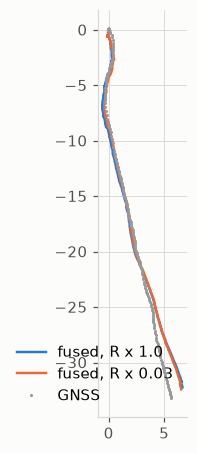

In [13]:
res = en - (q @ A[:2, :2].T + A[:2, 2])
lag = lambda x, k: np.corrcoef(x[:-k], x[k:])[0, 1]
print(f"GNSS residuals to the aligned odometry: sigma {res.std(axis=0).round(2)} m (receiver says {np.sqrt(var.mean(axis=0)).round(1)})")
print(f"autocorrelation east: lag 1 (0.25 s) {lag(res[:, 0], 1):.3f}, lag 16 (4 s) {lag(res[:, 0], 16):.2f}")
P0r = np.diag([var[0, 0], var[0, 1], np.radians(10) ** 2])
for scale in (1.0, 0.03):
    r = fusion.fuse(list(ts), odo_r, list(tf), en, var, x0, P0r, noise, 0.99, scale)
    print(f"R x {scale}: mean NIS {np.mean(r['nis']):.2f}, final heading {np.degrees(r['x'][-1, 2]):.1f} ± {np.degrees(r['sigma'][-1, 2]):.2f} deg")
    plt.plot(r["x"][:, 0], r["x"][:, 1], label=f"fused, R x {scale}")
plt.plot(en[:, 0], en[:, 1], ".", ms=2, color="0.6", label="GNSS"); plt.gca().set_aspect("equal"); plt.legend(); plt.show()

## 🔨 Break it — no gate

In [14]:
print("gate on :", stats(outlier_fraction=0.05))
print("gate off:", stats(outlier_fraction=0.05, gate=0.0))

gate on : [0.73 1.95 1.  ]


gate off: [ 1.39 10.46  1.93]


## 🔨 Break it — a wrong initial heading

Start 90° off. With a small heading uncertainty the first fixes look like outliers and the gate rejects them; with
an honest uncertainty the filter recovers.

In [15]:
for sigma_deg in (5, 90):
    r = fusion.fuse(list(t), odo, list(tg), zg, np.full((len(tg), 2), 2.25), truth[0] + [0, 0, np.pi / 2],
                    np.diag([1, 1, np.radians(sigma_deg) ** 2]), noise)
    print(f"sigma_psi {sigma_deg:2d} deg: {np.mean(r['accepted']):.0%} of fixes accepted, RMS error {rms(r['x'][:, :2] - truth[:, :2]):.1f} m")

sigma_psi  5 deg: 3% of fixes accepted, RMS error 115.3 m
sigma_psi 90 deg: 95% of fixes accepted, RMS error 1.1 m


## What to remember

- Odometry predicts, GNSS corrects; the position updates also correct the heading through the covariance.
- Gate on the NIS: outliers then cost nothing.
- A consistent filter has NIS ≈ 2 *and* errors that match its covariance; the second needs a reference to check.
- Unmodelled odometry errors and time-correlated GNSS errors make the filter overconfident.
- Receivers' reported covariances can be far off — here 60 times too pessimistic in NIS.